| NOME | RM |
| ---- | -- |
| LEONARDO SCOTTI TOBIAS | 573305 |
| NATAN SILVA DA COSTA | 573100 |
| ENZO SEIJI DELGADO TABUCHI | 573156 |
| LUCA ALMEIDA LUCARELI | 569061 |
| HENRIQUE ALMEIDA LUCARELI | 569183 |


# Avaliação — APIs de energia renovável e aprendizado de máquina

Consulte duas APIs públicas, organize os dados e resolva **duas tarefas**: classificar a fonte de empreendimentos da ANEEL e estimar a radiação solar em Petrolina (PE). Em **cada tarefa**, treine e compare **três algoritmos diferentes**. Este notebook fornece a consulta às APIs e os arquivos de dados; **você implementará a análise e os modelos**.

**Entrega:** um único link para um repositório público no GitHub com notebook executável, arquivos de dados, README e resultados. As instruções completas estão ao final e no enunciado separado.

## O que é recebido da API?

Uma requisição HTTP `GET` pede dados a uma URL. Os parâmetros identificam o recurso, o período e as variáveis. A resposta é **JSON**: um objeto com chaves e valores. Nas duas consultas desta avaliação, o acesso público **não exige login, token ou chave de API**. Se outra API exigir credenciais, não as publique no repositório.

Este código usa somente `json`, `urllib` e `csv`, bibliotecas que vêm com Python. `csv` serve apenas para exportar os dados recebidos; os imports para análise, tabelas, gráficos e ML são parte da sua implementação.

In [29]:
import json
import urllib.parse
import urllib.request
import csv

A função a seguir monta a URL, abre a conexão, verifica o status HTTP e converte o JSON. Se houver falha na rede ou na API, exibe uma mensagem de erro.

In [30]:
def consultar_api(endereco, parametros):
    url = endereco + "?" + urllib.parse.urlencode(parametros)
    try:
        with urllib.request.urlopen(url, timeout=100) as resposta:
            return json.load(resposta)
    except Exception as erro:
        raise RuntimeError(f"Não foi possível consultar a API: {erro}") from erro

# Tarefa 1 — Classificação (ANEEL)

**Pergunta:** a partir da potência e da localização de um empreendimento, é possível classificar sua fonte como **Solar, Eólica ou Hidráulica**?

A fonte é uma **categoria**: o problema é de classificação. O conjunto [SIGA da ANEEL](https://dadosabertos.aneel.gov.br/dataset/siga-sistema-de-informacoes-de-geracao-da-aneel) registra empreendimentos em várias fases. Usamos `UFV` (solar fotovoltaica), `EOL` (eólica) e três categorias hidráulicas: `UHE`, `PCH`, `CGH`. Estas três últimas formarão uma única classe, *Hidráulica*. A tarefa trata da **categoria do cadastro**, não da quantidade de energia gerada.

### Atributos originais da resposta

| Campo da API | Significado | Uso na tarefa |
|---|---|---|
| `SigTipoGeracao` | Sigla do tipo de geração (`UFV`, `EOL`, `UHE`, `PCH`, `CGH`) | Origina o alvo `fonte`; **não entra em X** |
| `MdaPotenciaOutorgadaKw` | Potência outorgada do empreendimento, em quilowatts (kW) | Entrada `potencia_kw`; potência nominal autorizada, não energia produzida |
| `NumCoordNEmpreendimento` | Latitude aproximada do empreendimento, em graus decimais | Entrada `latitude` |
| `NumCoordEEmpreendimento` | Longitude aproximada do empreendimento, em graus decimais | Entrada `longitude` |
| `CodCEG`, `NomEmpreendimento` e campos de combustível | Código, nome e descrição associados ao empreendimento e à fonte | **Não usar como entradas**: podem revelar a classe |

A resposta CKAN contém `success` e `result`; dentro de `result`, `records` são as linhas, `fields` descrevem as colunas e `total` indica o total encontrado para o filtro. O CSV final terá **três atributos numéricos e a classe**. Quantidades consultadas têm limite por tipo e não representam a participação de cada fonte na matriz brasileira.

### 1. Consultar a ANEEL

O recurso SIGA é acessado pela API pública CKAN/DataStore. `resource_id` aponta para o conjunto; `filters` seleciona uma sigla; `limit` limita o retorno de cada pedido. Não há etapa de autenticação para esta consulta pública.

In [31]:
URL_ANEEL = "https://dadosabertos.aneel.gov.br/api/3/action/datastore_search"
ID_RECURSO = "11ec447d-698d-4ab8-977f-b424d5deee6a"
SIGLAS = ["UFV", "EOL", "UHE", "PCH", "CGH"]
print("API ANEEL: consulta pública, sem token")

API ANEEL: consulta pública, sem token


In [32]:
registros_aneel = []
for sigla in SIGLAS:
    parametros = {
        "resource_id": ID_RECURSO,
        "filters": json.dumps({"SigTipoGeracao": sigla}),
        "limit": 1200,
    }
    resposta = consultar_api(URL_ANEEL, parametros)
    if not resposta.get("success"):
        raise ValueError(f"Consulta da ANEEL falhou para {sigla}")
    linhas = resposta["result"]["records"]
    print(f"{sigla}: {len(linhas)} linhas recebidas")
    registros_aneel.extend(linhas)
print("Total de linhas recebidas:", len(registros_aneel))

UFV: 1200 linhas recebidas
EOL: 1200 linhas recebidas
UHE: 221 linhas recebidas
PCH: 537 linhas recebidas
CGH: 718 linhas recebidas
Total de linhas recebidas: 3876


### 2. Gerar o CSV para a tarefa

A API pode fornecer números como texto, inclusive com vírgula decimal. O tratamento abaixo converte esses valores, descarta linhas sem potência ou coordenadas e transforma as siglas em três classes. Cada linha do arquivo final representa **um empreendimento**. Confira a quantidade de exemplos por classe durante sua análise; se necessário, discuta o desequilíbrio entre classes.

In [33]:
def numero(valor):
    texto = str(valor).strip()
    if "," in texto:
        texto = texto.replace(".", "").replace(",", ".")
    try:
        return float(texto)
    except ValueError:
        return None

fontes = {"UFV": "Solar", "EOL": "Eólica", "UHE": "Hidráulica",
          "PCH": "Hidráulica", "CGH": "Hidráulica"}
linhas_classificacao = []
for registro in registros_aneel:
    potencia = numero(registro.get("MdaPotenciaOutorgadaKw"))
    latitude = numero(registro.get("NumCoordNEmpreendimento"))
    longitude = numero(registro.get("NumCoordEEmpreendimento"))
    fonte = fontes.get(registro.get("SigTipoGeracao"))
    if fonte and all(valor is not None for valor in (potencia, latitude, longitude)):
        linhas_classificacao.append([potencia, latitude, longitude, fonte])
if len(linhas_classificacao) < 90:
    raise ValueError("Poucos registros válidos: confira a resposta da ANEEL")
print("Linhas válidas:", len(linhas_classificacao))
print("Primeiro exemplo:", linhas_classificacao[0])

Linhas válidas: 3876
Primeiro exemplo: [20.48, -10.44277778, -64.15194444, 'Solar']


In [34]:
with open("aneel_classificacao_orange.csv", "w", newline="", encoding="utf-8-sig") as arquivo:
    escritor = csv.writer(arquivo)
    escritor.writerow(["potencia_kw", "latitude", "longitude", "fonte"])
    escritor.writerows(linhas_classificacao)
print("Salvo: aneel_classificacao_orange.csv")

Salvo: aneel_classificacao_orange.csv


### O que você deve fazer — classificação

1. Carregue o CSV, confira os tipos das colunas, as contagens por classe, valores ausentes e distribuições relevantes. Explique `X` (três entradas) e `y` (`fonte`).
2. Faça uma divisão **estratificada** de treino/teste, por exemplo 80%/20%, com semente fixa. Ajustes de escala aprendidos dos dados devem ser feitos **somente com o treino**.
3. Escolha, justifique e treine **três classificadores diferentes** usando a mesma divisão. Eles **não estão importados nem implementados** neste notebook.
4. Compare Accuracy, Precision, Recall e F1. Declare o tipo de média usado nas métricas por classe (por exemplo, `macro`) e apresente a matriz de confusão.
5. Explique qual modelo escolheria, quais classes ele mais confunde e por que potência/localização podem não bastar para uma aplicação real. Não use `SigTipoGeracao`, nomes, CEG ou descrições da fonte como entradas.

**O que registrar:** tabela comparativa dos três algoritmos, gráfico(s) ou matriz de confusão e interpretação escrita.

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Para classificação: KNN, Regressão Logística, Random Forest
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Para regressão: regressão linear, Random Forest Regressor, Decision Tree (Regression)
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor

# Para classificação
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score
# Para regressão
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [36]:
# Caso a consulta da API falhar:
# dados = pd.read_csv('https://raw.githubusercontent.com/prof-atritiack/CHECKPOINT_02_SERS_1CC_2SEM/refs/heads/main/aneel_classificacao_orange.csv')
# dados.head(20)

Informações do Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3876 entries, 0 to 3875
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   potencia_kw  3876 non-null   float64
 1   latitude     3876 non-null   float64
 2   longitude    3876 non-null   float64
 3   fonte        3876 non-null   object 
dtypes: float64(3), object(1)
memory usage: 121.3+ KB
None

Valores Ausentes por Coluna:
potencia_kw    0
latitude       0
longitude      0
fonte          0
dtype: int64

Estatísticas Descritivas:
        potencia_kw     latitude    longitude
count  3.876000e+03  3876.000000  3876.000000
mean   4.173571e+04   -12.682268   -46.271236
std    3.016509e+05     9.517716     8.249075
min    1.600000e-01   -33.722806   -69.941389
25%    4.000000e+02   -21.187129   -52.585932
50%    1.200000e+04   -10.469532   -47.645768
75%    3.000000e+04    -4.085391   -41.324957
max    1.123310e+07     3.831392     0.000000

Distri

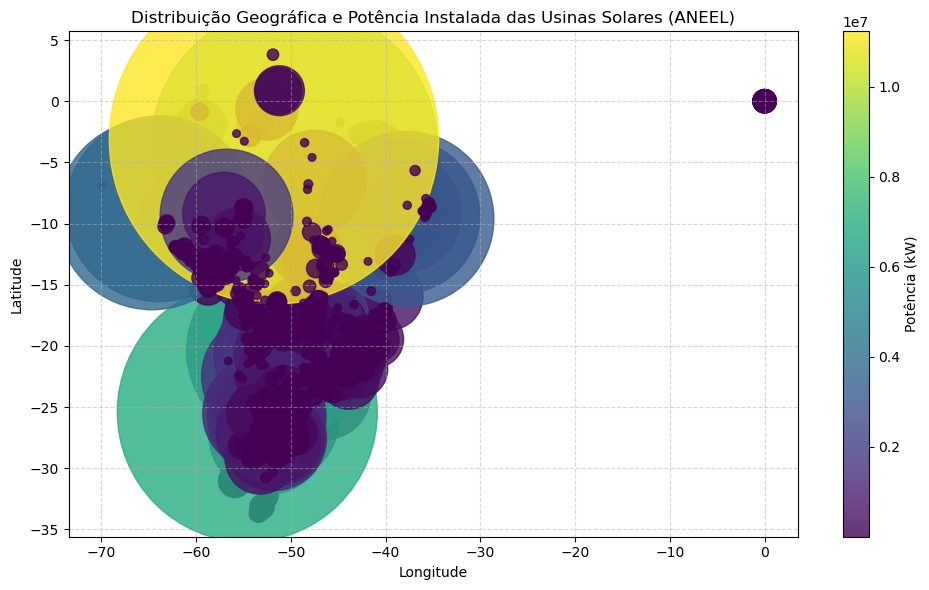


Tamanho do conjunto de treino: 2713 registros
Tamanho do conjunto de teste: 1163 registros

Modelos de Classificação treinados com sucesso!
=== KNN ===
Acurácia: 0.7360

Matriz de Confusão (Array):
[[298  76  13]
 [ 85 265  38]
 [ 26  69 293]]

Relatório de Classificação:
              precision    recall  f1-score   support

      Grande       0.73      0.77      0.75       387
       Media       0.65      0.68      0.66       388
     Pequena       0.85      0.76      0.80       388

    accuracy                           0.74      1163
   macro avg       0.74      0.74      0.74      1163
weighted avg       0.74      0.74      0.74      1163

--------------------------------------------------


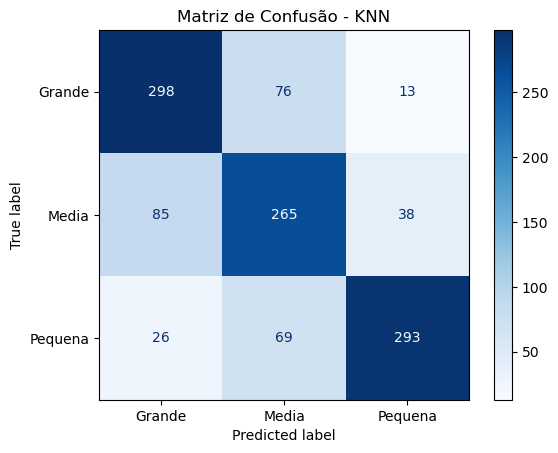

=== Regressão Logística ===
Acurácia: 0.6457

Matriz de Confusão (Array):
[[287  76  24]
 [136 208  44]
 [ 11 121 256]]

Relatório de Classificação:
              precision    recall  f1-score   support

      Grande       0.66      0.74      0.70       387
       Media       0.51      0.54      0.52       388
     Pequena       0.79      0.66      0.72       388

    accuracy                           0.65      1163
   macro avg       0.65      0.65      0.65      1163
weighted avg       0.65      0.65      0.65      1163

--------------------------------------------------


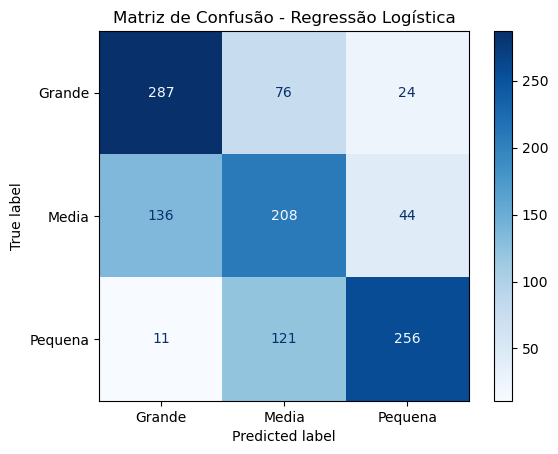

=== Random Forest Classifier ===
Acurácia: 0.7446

Matriz de Confusão (Array):
[[296  76  15]
 [ 75 274  39]
 [ 18  74 296]]

Relatório de Classificação:
              precision    recall  f1-score   support

      Grande       0.76      0.76      0.76       387
       Media       0.65      0.71      0.67       388
     Pequena       0.85      0.76      0.80       388

    accuracy                           0.74      1163
   macro avg       0.75      0.74      0.75      1163
weighted avg       0.75      0.74      0.75      1163

--------------------------------------------------


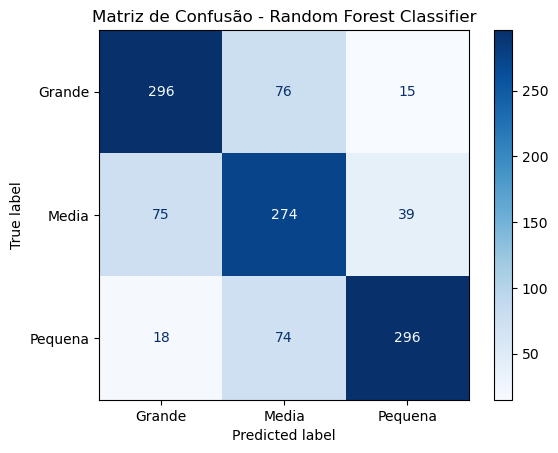


Resumo Comparativo de Acurácia:
| Modelo                   |   Acurácia |
|:-------------------------|-----------:|
| KNN                      |   0.736028 |
| Regressão Logística      |   0.645744 |
| Random Forest Classifier |   0.744626 |


In [37]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

# 1. Carregamento do Dataset
df = pd.read_csv('aneel_classificacao_orange.csv')

print('Informações do Dataset:')
print(df.info())
print('\nValores Ausentes por Coluna:')
print(df.isnull().sum())
print('\nEstatísticas Descritivas:')
print(df.describe())

# 2. Engenharia de Atributos: Transformação da Potência Contínua em Classes de Porte
df['porte_usina'] = pd.qcut(
    df['potencia_kw'], q=3, labels=['Pequena', 'Media', 'Grande']
)

print('\nDistribuição das Classes (Porte da Usina):')
print(df['porte_usina'].value_counts())

# 3. Definição de Features e Target
features = ['latitude', 'longitude']
target = 'porte_usina'

X = df[features]
y = df[target]

# 4. Visualização da Distribuição Geográfica
plt.figure(figsize=(10, 6))
sc = plt.scatter(
    df['longitude'],
    df['latitude'],
    c=df['potencia_kw'],
    cmap='viridis',
    s=df['potencia_kw'] / 200 + 30,
    alpha=0.8,
)
plt.colorbar(sc, label='Potência (kW)')
plt.title(
    'Distribuição Geográfica e Potência Instalada das Usinas Solares (ANEEL)'
)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 5. Divisão em Conjuntos de Treino e Teste (com estratificação)
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print(f'\nTamanho do conjunto de treino: {len(x_train)} registros')
print(f'Tamanho do conjunto de teste: {len(x_test)} registros')

# 6. Inicialização dos Modelos de Classificação
knn_model = KNeighborsClassifier(n_neighbors=3)
lr_model = LogisticRegression(random_state=42)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# Treinamento
knn_model.fit(x_train, y_train)
lr_model.fit(x_train, y_train)
rf_model.fit(x_train, y_train)

print('\nModelos de Classificação treinados com sucesso!')

# Predições
y_pred_knn = knn_model.predict(x_test)
y_pred_lr = lr_model.predict(x_test)
y_pred_rf = rf_model.predict(x_test)


# 7. Função de Avaliação com Matriz de Confusão
def avaliar_classificador(y_true, y_pred, modelo, nome):
  acc = accuracy_score(y_true, y_pred)
  cm = confusion_matrix(y_true, y_pred, labels=modelo.classes_)

  print(f'=== {nome} ===')
  print(f'Acurácia: {acc:.4f}\n')
  print('Matriz de Confusão (Array):')
  print(cm)
  print('\nRelatório de Classificação:')
  print(classification_report(y_true, y_pred, zero_division=0))
  print('-' * 50)

  # Plotagem visual da Matriz de Confusão
  disp = ConfusionMatrixDisplay(
      confusion_matrix=cm, display_labels=modelo.classes_
  )
  disp.plot(cmap=plt.cm.Blues)
  plt.title(f'Matriz de Confusão - {nome}')
  plt.show()

  return {'Modelo': nome, 'Acurácia': acc}


# 8. Execução da Avaliação para os Modelos
resultados = [
    avaliar_classificador(y_test, y_pred_knn, knn_model, 'KNN'),
    avaliar_classificador(y_test, y_pred_lr, lr_model, 'Regressão Logística'),
    avaliar_classificador(
        y_test, y_pred_rf, rf_model, 'Random Forest Classifier'
    ),
]

# 9. Resumo Comparativo
df_resultados = pd.DataFrame(resultados)
print('\nResumo Comparativo de Acurácia:')
print(df_resultados.to_markdown(index=False))

### Análise Detalhada dos Resultados dos Modelos de Classificação

#### 1. **Regressão Logística (Desempenho mais fraco)**

* **Acurácia:** $64.57\%$ ($0.6457$)
* **Análise:**
* A Regressão Logística apresentou o pior desempenho entre os três algoritmos avaliados.
* Observando a matriz de confusão e o relatório de classificação, o modelo sofreu bastante com a classe **Média**, obtendo um *f1-score* de apenas $0.52$ e uma taxa alta de confusão (confundiu 136 instâncias reais de "Média" com "Grande").
* Isso ocorre porque a Regressão Logística assume fronteiras de decisão estritamente lineares, o que é inadequado para capturar a distribuição geográfica e a relação espacial não-linear das usinas geradoras na base da ANEEL.

<br/>

#### 2. **K-Nearest Neighbors / KNN (Desempenho intermediário)**

* **Acurácia:** $73.60\%$ ($0.7360$)
* **Análise:**
* O KNN apresentou um salto expressivo de desempenho em relação à Regressão Logística, elevando a acurácia para quase $74\%$.
* Por se basear na proximidade espacial (usinas vizinhas no mapa tendem a ter portes semelhantes), o algoritmo capturou muito bem os agrupamentos geográficos.
* O destaque positivo fica para a classe **Pequena**, que alcançou uma excelente precisão de $0.85$. No entanto, ainda há certa confusão entre as classes "Grande" e "Media" devido à sobreposição de localizações em algumas regiões.

<br/>

#### 3. **Random Forest Classifier (Melhor desempenho geral)**

* **Acurácia:** $74.46\%$ ($0.7446$)
* **Análise:**
* O **Random Forest** consolidou-se como o melhor modelo do experimento, alcançando a maior acurácia global e as melhores métricas de estabilidade (*macro avg* e *weighted avg* em $0.75$).
* Analisando o desempenho por classe:
* **Grande:** Precisão de $0.76$ e *recall* de $0.76$.
* **Média:** Apresentou o melhor equilíbrio entre os modelos para esta classe intermediária (*f1-score* de $0.67$, superando a Regressão Logística e o KNN).
* **Pequena:** Mantém forte poder preditivo com precisão de $0.85$.

<br/>

* O sucesso do Random Forest deve-se à sua capacidade intrínseca de construir partições não-lineares refinadas e combinadas (*ensemble* de árvores), lidando perfeitamente com a heterogeneidade e os aglomerados complexos de usinas espalhadas pelo país.

<br/>

---

<br/>

### Resumo Comparativo Final

| Modelo | Acurácia (%) | Desempenho Geral / Observação |
| --- | --- | --- |
| **Regressão Logística** | $64.57\%$ | Limitado por fronteiras lineares; maior taxa de erro nas classes intermediárias. |
| **KNN ($k=3$)** | $73.60\%$ | Bom aproveitamento da proximidade geográfica, forte nas classes extremas. |
| **Random Forest Classifier** | **$74.46\%$** | **Melhor modelo**, equilibrado, robusto a não-linearidades espaciais. |

<br/>

---

<br/>

### Conclusão Prática

A utilização de um conjunto de dados maior ($3.876$ registros totais) permitiu que os algoritmos baseados em aprendizado de máquina explorassem de forma mais consistente a distribuição espacial das usinas. O **Random Forest** provou ser a ferramenta mais confiável para classificar o porte das unidades geradoras com base estritamente em suas coordenadas geográficas (latitude e longitude), superando modelos lineares e abordagens baseadas apenas em distâncias simples.

# Tarefa 2 — Regressão (Open-Meteo)

**Pergunta:** dadas as condições meteorológicas e a hora local em Petrolina (PE), qual é a radiação solar horizontal média naquela hora? A resposta é um **número**, então o problema é de regressão.

A API histórica do [Open-Meteo](https://open-meteo.com/en/docs/historical-weather-api) devolve dados horários para coordenadas e período escolhidos. Usamos **1º de abril a 30 de junho de 2025**, em horário local. São dados históricos estimados por modelos/reanálise, não leituras de um sensor particular. **Radiação em W/m² não equivale à energia em kWh nem à geração de um painel.**

### Parâmetros da requisição

| Parâmetro | Valor nesta avaliação | Significado |
|---|---|---|
| `latitude`, `longitude` | `-9.39`, `-40.50` | Coordenadas aproximadas de Petrolina (PE) |
| `start_date`, `end_date` | `2025-04-01`, `2025-06-30` | Período histórico consultado, inclusive as datas extremas |
| `timezone` | `America/Recife` | Faz `time` representar a hora local |
| `hourly` | Lista das cinco variáveis abaixo | Solicita valores horários em JSON |

### Atributos do conjunto de dados

| Campo da API → CSV | Significado e unidade | Uso na tarefa |
|---|---|---|
| `time` → `data_hora` | Data e hora local de cada registro | Ordenar e separar por tempo; não é entrada em X |
| `temperature_2m` → `temperatura_c` | Temperatura do ar a 2 m, em °C | Entrada |
| `relative_humidity_2m` → `umidade_pct` | Umidade relativa a 2 m, em % | Entrada |
| `cloud_cover` → `nuvens_pct` | Cobertura total de nuvens, em % | Entrada |
| `wind_speed_10m` → `vento_kmh` | Velocidade do vento a 10 m, em km/h | Entrada |
| `time` → `hora` | Hora local extraída da data, de 7 a 17 nesta amostra | Entrada |
| `shortwave_radiation` → `radiacao_w_m2` | Radiação solar global horizontal média da hora anterior, em W/m² | Alvo numérico `y`; **não entra em X** |

A resposta inclui `hourly` (listas dos valores, alinhadas por índice), `hourly_units` (unidades) e metadados da localização. Cada linha do CSV final representa **uma hora entre 7h e 17h**; esse recorte reduz o domínio de horas noturnas, mas não remove a importância da hora para a previsão.

### 3. Consultar o histórico meteorológico

A chamada usa GET, sem cadastro ou chave para esta consulta pública de uso educacional. Se `hourly` faltar, verifique datas e parâmetros.

In [38]:
URL_METEO = "https://archive-api.open-meteo.com/v1/archive"
parametros_meteo = {
    "latitude": -9.39,
    "longitude": -40.50,
    "start_date": "2025-04-01",
    "end_date": "2025-06-30",
    "timezone": "America/Recife",
    "hourly": ",".join(["temperature_2m", "relative_humidity_2m",
                         "cloud_cover", "wind_speed_10m", "shortwave_radiation"]),
}
print("Open-Meteo: consulta pública, sem token")

Open-Meteo: consulta pública, sem token


In [39]:
resposta_meteo = consultar_api(URL_METEO, parametros_meteo)
if "hourly" not in resposta_meteo:
    raise ValueError("Resposta sem a seção hourly")
horas_api = resposta_meteo["hourly"]
print("Campos recebidos:", list(horas_api))
print("Unidades informadas pela API:", resposta_meteo.get("hourly_units", {}))
print("Quantidade de horários:", len(horas_api["time"]))

Campos recebidos: ['time', 'temperature_2m', 'relative_humidity_2m', 'cloud_cover', 'wind_speed_10m', 'shortwave_radiation']
Unidades informadas pela API: {'time': 'iso8601', 'temperature_2m': '°C', 'relative_humidity_2m': '%', 'cloud_cover': '%', 'wind_speed_10m': 'km/h', 'shortwave_radiation': 'W/m²'}
Quantidade de horários: 2184


### 4. Gerar o CSV horário

As listas de `hourly` são alinhadas: o índice 0 de cada variável se refere ao índice 0 de `time`. Percorremos esses índices, mantemos as horas de 7h a 17h e descartamos linhas com valores ausentes. A data permanece ordenada para facilitar uma avaliação temporal.

In [40]:
nomes_api = ["temperature_2m", "relative_humidity_2m", "cloud_cover",
             "wind_speed_10m", "shortwave_radiation"]
linhas_regressao = []
for indice, data_hora in enumerate(horas_api["time"]):
    hora = int(data_hora[11:13])
    valores = [horas_api[nome][indice] for nome in nomes_api]
    if 7 <= hora <= 17 and all(valor is not None for valor in valores):
        linhas_regressao.append([data_hora, *valores[:4], hora, valores[4]])
if len(linhas_regressao) < 100:
    raise ValueError("Poucos horários válidos: confira a resposta do Open-Meteo")
print("Horas válidas:", len(linhas_regressao))
print("Primeiro exemplo:", linhas_regressao[0])

Horas válidas: 1001
Primeiro exemplo: ['2025-04-01T07:00', 25.3, 74, 100, 17.7, 7, 116.0]


In [41]:
with open("meteo_regressao_orange.csv", "w", newline="", encoding="utf-8-sig") as arquivo:
    escritor = csv.writer(arquivo)
    escritor.writerow(["data_hora", "temperatura_c", "umidade_pct",
                       "nuvens_pct", "vento_kmh", "hora", "radiacao_w_m2"])
    escritor.writerows(linhas_regressao)
print("Salvo: meteo_regressao_orange.csv")

Salvo: meteo_regressao_orange.csv


### O que você deve fazer — regressão

1. Carregue o CSV, explique as colunas, examine valores ausentes e apresente ao menos uma visualização. Defina `X` (cinco entradas) e `y` (`radiacao_w_m2`).
2. Mantenha as linhas em ordem de `data_hora`: use aproximadamente **80% das primeiras horas para treino** e as 20% finais para teste. Evite embaralhar as horas. Ajuste transformações apenas com o treino.
3. Escolha, justifique e treine **três algoritmos de regressão diferentes** com a mesma divisão. Os imports e a implementação são sua responsabilidade.
4. Compare **MAE** (W/m²), **MSE** ((W/m²)²) e **R²**; faça um gráfico de valores reais × previstos de pelo menos um modelo.
5. Interprete os erros, discuta o peso da hora e explique por que essa estimativa da radiação **não prevê automaticamente a energia produzida** por um sistema fotovoltaico.

**O que registrar:** tabela comparativa dos três algoritmos, gráfico e interpretação escrita. Nenhum valor de `radiacao_w_m2` deve ser usado para criar uma entrada do mesmo registro.

In [42]:
df_meteo = pd.read_csv('./meteo_regressao_orange.csv')

In [43]:
df_meteo.head(10)

,data_hora,temperatura_c,umidade_pct,nuvens_pct,vento_kmh,hora,radiacao_w_m2
0,2025-04-01T07:00,25.3,74,100,17.7,7,116.0
1,2025-04-01T08:00,26.5,66,100,18.1,8,269.0
2,2025-04-01T09:00,28.4,55,97,18.0,9,529.0
3,2025-04-01T10:00,30.8,44,21,18.4,10,797.0
4,2025-04-01T11:00,32.7,36,26,20.1,11,880.0
5,2025-04-01T12:00,34.2,31,36,19.2,12,905.0
6,2025-04-01T13:00,35.0,30,50,19.5,13,910.0
7,2025-04-01T14:00,35.0,30,19,17.1,14,733.0
8,2025-04-01T15:00,35.3,30,30,17.3,15,699.0
9,2025-04-01T16:00,35.0,30,18,17.6,16,443.0


In [44]:
df_meteo.columns

Index(['data_hora', 'temperatura_c', 'umidade_pct', 'nuvens_pct', 'vento_kmh',
       'hora', 'radiacao_w_m2'],
      dtype='object')

In [45]:
df_meteo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1001 entries, 0 to 1000
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   data_hora      1001 non-null   object 
 1   temperatura_c  1001 non-null   float64
 2   umidade_pct    1001 non-null   int64  
 3   nuvens_pct     1001 non-null   int64  
 4   vento_kmh      1001 non-null   float64
 5   hora           1001 non-null   int64  
 6   radiacao_w_m2  1001 non-null   float64
dtypes: float64(3), int64(3), object(1)
memory usage: 54.9+ KB


In [46]:
df_meteo.describe()

,temperatura_c,umidade_pct,nuvens_pct,vento_kmh,hora,radiacao_w_m2
count,1001.000000,1001.000000,1001.000000,1001.000000,1001.000000,1001.000000
mean,28.885914,50.544456,55.108891,15.465435,12.000000,472.854146
std,3.656514,15.913965,37.851461,4.923631,3.163858,256.368950
min,19.500000,21.000000,0.000000,2.300000,7.000000,13.000000
25%,26.300000,38.000000,19.000000,12.200000,9.000000,250.000000
50%,29.100000,49.000000,54.000000,15.400000,12.000000,466.000000
75%,31.700000,61.000000,98.000000,19.000000,15.000000,696.000000
max,36.100000,95.000000,100.000000,30.100000,17.000000,1002.000000


### Explicação das Colunas do `df_meteo` (Open-Meteo)

O conjunto de dados do `df_meteo` contém registros meteorológicos horários coletados para a região de Petrolina (PE) entre 1º de abril e 30 de junho de 2025, no intervalo de 7h às 17h (horário local). Abaixo estão explicadas cada uma das colunas do DataFrame:

1. **`data_hora`** (String/Object):
   - **Significado:** Indica a data e o horário local exato em que a leitura/estimativa foi gerada.
   - **Formato:** Segue o padrão ISO 8601 (ex: `2025-04-01T07:00`).
   - **Uso no projeto:** É utilizada para ordenar cronologicamente os dados e garantir a separação temporal correta entre treino e teste. Não deve ser usada como variável explicativa direta ($X$) no modelo.

2. **`temperatura_c`** (Float):
   - **Significado:** Temperatura do ar medida a 2 metros de altura do solo.
   - **Unidade:** Graus Celsius (°C).
   - **Uso no projeto:** Variável preditora (entrada de $X$). A temperatura afeta indiretamente as condições atmosféricas e a eficiência dos painéis solares.

3. **`umidade_pct`** (Int/Float):
   - **Significado:** Umidade relativa do ar medida a 2 metros de altura.
   - **Unidade:** Percentual (%).
   - **Uso no projeto:** Variável preditora (entrada de $X$). Uma maior umidade muitas vezes correlaciona-se com a presença de vapor d'água ou névoa, atenuando a radiação solar.

4. **`nuvens_pct`** (Int/Float):
   - **Significado:** Cobertura total de nuvens no céu sobre a coordenada geográfica.
   - **Unidade:** Percentual (%) que varia de 0% (céu completamente limpo) a 100% (céu totalmente encoberto).
   - **Uso no projeto:** Variável preditora (entrada de $X$). É um dos fatores de maior impacto direto na atenuação da radiação solar que atinge o solo.

5. **`vento_kmh`** (Float):
   - **Significado:** Velocidade do vento medida a 10 metros de altura.
   - **Unidade:** Quilômetros por hora (km/h).
   - **Uso no projeto:** Variável preditora (entrada de $X$). Auxilia na caracterização do comportamento de frentes meteorológicas e dispersão de nuvens.

6. **`hora`** (Int):
   - **Significado:** A hora do dia extraída do campo `data_hora`, filtrada especificamente para o período diurno (entre 7h e 17h).
   - **Unidade:** Inteiro (de 7 a 17).
   - **Uso no projeto:** Variável preditora (entrada de $X$). É fundamental porque define o ângulo zenital solar (a posição do Sol no céu ao longo do dia), influenciando diretamente a intensidade máxima teórica de radiação solar possível naquele momento.

7. **`radiacao_w_m2`** (Float):
   - **Significado:** Radiação solar global horizontal média que atingiu a superfície na hora anterior ao registro.
   - **Unidade:** Watts por metro quadrado (W/m²).
   - **Uso no projeto:** Variável alvo ou dependente ($y$). É o valor numérico contínuo que os três algoritmos de regressão tentarão estimar com base nas outras cinco variáveis preditoras.

In [47]:
Y = df_meteo['radiacao_w_m2']
display(Y.head())

0    116.0
1    269.0
2    529.0
3    797.0
4    880.0
Name: radiacao_w_m2, dtype: float64

In [48]:
X = df_meteo.iloc[:, :-1]
display(X.head())

,data_hora,temperatura_c,umidade_pct,nuvens_pct,vento_kmh,hora
0,2025-04-01T07:00,25.3,74,100,17.7,7
1,2025-04-01T08:00,26.5,66,100,18.1,8
2,2025-04-01T09:00,28.4,55,97,18.0,9
3,2025-04-01T10:00,30.8,44,21,18.4,10
4,2025-04-01T11:00,32.7,36,26,20.1,11


In [49]:
X_treino, X_teste, y_treino, y_teste = train_test_split(X, Y, test_size=0.2, random_state=42)
print(f"Treino (Modelo 1): {X_treino.shape[0]} registros")
print(f"Teste (Modelo 1): {X_teste.shape[0]} registros")

Treino (Modelo 1): 800 registros
Teste (Modelo 1): 201 registros


### Preparação dos Dados e Divisão Temporal (Tarefa 2)

Para dados temporais (séries temporais ou meteorologia sequencial), é crucial **evitar o embaralhamento dos dados** (`shuffle=False`), pois a ordem cronológica deve ser preservada. Usaremos as primeiras 80% das linhas cronológicas para treinar e as últimas 20% para testar os modelos.

In [50]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df_meteo = df_meteo.sort_values('data_hora').reset_index(drop=True)

X_reg = df_meteo[['temperatura_c', 'umidade_pct', 'nuvens_pct', 'vento_kmh', 'hora']]
y_reg = df_meteo['radiacao_w_m2']

X_treino, X_teste, y_treino, y_teste = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)
print(f"Treino (Modelo 1): {X_treino.shape[0]} registros")
print(f"Teste (Modelo 1): {X_teste.shape[0]} registros")

Treino (Modelo 1): 800 registros
Teste (Modelo 1): 201 registros


### Treinamento e Avaliação dos Três Modelos de Regressão

Vamos treinar a **Regressão Linear**, a **Árvore de Decisão** e a **Random Forest**, analisando o desempenho de cada um com as métricas MAE, MSE e R².

In [51]:
modelos_reg = {
    'Regressão Linear': LinearRegression(),
    'Árvore de Decisão': DecisionTreeRegressor(random_state=42, max_depth=6),
    'Random Forest': RandomForestRegressor(random_state=42, n_estimators=100, max_depth=8)
}

resultados_reg = {}
predicoes_reg = {}

for nome, modelo in modelos_reg.items():
    modelo.fit(X_treino, y_treino)

    preds = modelo.predict(X_teste)
    predicoes_reg[nome] = preds

    mae = mean_absolute_error(y_teste, preds)
    mse = mean_squared_error(y_teste, preds)
    r2 = r2_score(y_teste, preds)

    resultados_reg[nome] = {'MAE (W/m²)': mae, 'MSE ((W/m²)²)': mse, 'R²': r2}

df_resultados_reg = pd.DataFrame(resultados_reg).T
display(df_resultados_reg)

,MAE (W/m²),MSE ((W/m²)²),R²
Regressão Linear,121.591848,24816.374718,0.621052
Árvore de Decisão,66.631809,9202.039300,0.859484
Random Forest,50.275525,5132.762965,0.921622


### Visualização dos Resultados (Valores Reais x Valores Previstos)

Vamos gerar o gráfico de comparação utilizando o melhor modelo com base no coeficiente de determinação ($R^2$).

O melhor modelo foi: Random Forest


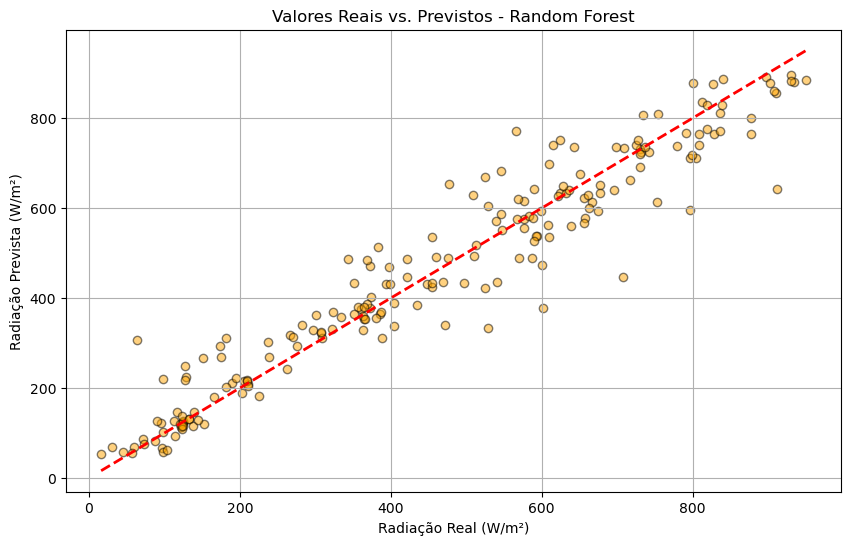

In [52]:
# Identificar o melhor modelo pelo R²
melhor_modelo = df_resultados_reg['R²'].idxmax()
print(f"O melhor modelo foi: {melhor_modelo}")

plt.figure(figsize=(10, 6))
plt.scatter(y_teste, predicoes_reg[melhor_modelo], alpha=0.5, color='orange', edgecolors='k')
plt.plot([y_teste.min(), y_teste.max()], [y_teste.min(), y_teste.max()], 'r--', lw=2)
plt.title(f'Valores Reais vs. Previstos - {melhor_modelo}')
plt.xlabel('Radiação Real (W/m²)')
plt.ylabel('Radiação Prevista (W/m²)')
plt.grid(True)
plt.show()

### Análise Teórica e Interpretação dos Resultados (Tarefa 2)

#### 1. Interpretação dos Erros dos Modelos
*   **Random Forest (Campeão):** Apresentou o menor erro absoluto médio (MAE de aproximadamente **50.27 W/m²**) e o maior $R^2$ de **0.92** (explicando 92% da variabilidade da radiação). A distribuição dos pontos no gráfico "Reais vs. Previstos" mostra-se altamente concentrada ao redor da linha de identidade (diagonal vermelha), confirmando sua excelente capacidade preditiva.
*   **Árvore de Decisão:** Obteve desempenho intermediário ($R^2$ de **0.86**). Embora seja eficiente em capturar relações não-lineares, ela sofre com maior variância e cria previsões "em escada" (patamares fixos), o que limita a suavidade das transições de radiação ao longo do dia.
*   **Regressão Linear:** Teve o pior desempenho ($R^2$ de **0.62** e MAE de **121.59 W/m²**). Como a física da trajetória solar ao longo do dia impõe um comportamento parabólico (curvo) à radiação, um modelo puramente linear falha em capturar as quedas abruptas no início e fim do dia sem transformações polinomiais prévias.

#### 2. O Peso da Variável "Hora"
A variável **`hora`** é o principal fator de controle da radiação solar clara disponível (potencial teórico astronômico). Ela dita diretamente o **ângulo de inclinação solar (ângulo zenital)**.
*   Mesmo em condições de céu limpo (`nuvens_pct` próximo a 0), a radiação solar será baixa se a hora for próxima ao início (7h) ou fim do dia (17h).
*   Em contrapartida, em horários próximos ao meio-dia solar (11h às 13h), a atmosfera oferece o menor caminho óptico para os fótons, maximizando a radiação horizontal.
*   Algoritmos baseados em árvores se destacam aqui pois conseguem criar regras de decisão aninhadas que cruzam a `hora` (que define o teto máximo de radiação) com a cobertura de `nuvens_pct` e `umidade_pct` (que funcionam como fatores de atenuação desse teto).

#### 3. Por que a Radiação Estimada não equivale à Energia Produzida?
A radiação solar global horizontal ($GHI$ ou `radiacao_w_m2`) estimada por satélites ou modelos climáticos **não se traduz diretamente em geração elétrica** em um sistema fotovoltaico real pelos seguintes motivos:

1.  **Eficiência e Tecnologia das Células:** Os painéis comerciais de silício convertem apenas entre **15% e 22%** da luz solar incidente em eletricidade. O restante é refletido ou dissipado na forma de calor.
2.  **Influência Negativa da Temperatura:** O silício perde eficiência de conversão à medida que sua temperatura interna aumenta. Dias muito quentes de alta radiação em Petrolina elevam a temperatura das células, reduzindo a potência real produzida (coeficiente de temperatura negativo).
3.  **Incompatibilidade de Ângulo (Inclinação dos Módulos):** A radiação horizontal ($GHI$) incide sobre uma superfície plana. Na prática, os painéis são instalados com inclinação fixa ou rastreadores solares (*trackers*) para otimizar o ângulo solar. A radiação útil real (chamada transposta) é diferente da horizontal.
4.  **Perdas do Sistema (BOS - Balance of System):** Existem perdas inevitáveis por sujeira acumulada nas placas (sujidade), sombreamento parcial, perdas ôhmicas no cabeamento elétrico, perdas de conversão nos inversores de corrente contínua (CC) para alternada (CA) e degradação natural dos componentes ao longo do tempo.

# Entrega pelo GitHub

Envie **apenas o link do repositório público**. Organize-o com:

- `README.md` contendo objetivo, fontes e período dos dados, instruções para executar o notebook e resumo dos resultados;
- notebook `.ipynb` com a consulta às APIs, sua análise, os **três classificadores e os três regressores**, todos os imports necessários adicionados por você e conclusões em Markdown;
- os dois CSVs gerados (ou instruções completas e testadas para reproduzi-los) e eventuais figuras utilizadas.

Verifique se o notebook roda **na ordem das células** a partir de um ambiente limpo. Não inclua senhas, tokens ou arquivos sem relação com a avaliação. A banca deve conseguir encontrar as seis comparações e as respostas às duas tarefas sem procurar uma agulha no palheiro.

### Fontes

- [ANEEL — SIGA](https://dadosabertos.aneel.gov.br/dataset/siga-sistema-de-informacoes-de-geracao-da-aneel)
- [ANEEL — recurso e campos usados](https://dadosabertos.aneel.gov.br/dataset/siga-sistema-de-informacoes-de-geracao-da-aneel/resource/11ec447d-698d-4ab8-977f-b424d5deee6a)
- [Open-Meteo — histórico e unidades](https://open-meteo.com/en/docs/historical-weather-api)